# Week 6: Hyperparameter tuning, learning rates, performance metrics, evaluation methods (dataset partitioning) #

# Hyperparameter tuning #

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error

# 1) Create the dataset using the provided code
data = {
    'Quizzes': [5.3, 5.5, 5.5, 5.0, 2.5, 3.0, 3.0, 3.1, 3.5, 3.5, 3.7, 4.0, 4.0, 4.0, 4.0, 5.7],
    'Labs': [5.3, 5.9, 5.29, 4.35, 5.5, 5.0, 4.0, 3.1, 4.5, 5.62, 5.0, 3.0, 4.0, 5.75, 4.44, 5.9],
    'Final': [4.818, 5.773, 4.464, 5.069, 4.164, 4.091, 3.727, 3.909, 3.518, 4.897, 5.209, 3.0, 3.091, 5.818, 4.069, 5.77]
}

# Convert to DataFrame
df = pd.DataFrame(data)

# Augmenting data by replicating and adding noise
np.random.seed(42)
augmented = []
for i in range(len(df)):
    row = df.iloc[i]
    for _ in range(10):  # Create 10 variations of each record
        noise = np.random.normal(0, 0.2, 3)  # Add Gaussian noise with mean=0 and std=0.2
        new_row = row + noise
        # Ensure values are within boundaries (grades must be between 2 and 6)
        new_row = new_row.clip(2, 6)
        augmented.append(new_row)

# Create augmented DataFrame
df_aug = pd.DataFrame(augmented, columns=df.columns)

# Extract the features we want to use: Labs vs Final
X = df_aug['Labs'].values.reshape(-1, 1)
y = df_aug['Final'].values

Train a linear regression with polynomial features to illustrate tuning of the learning rate in gradient descent, which is a sensitive hyperparameter.

The data are split into a training set and a **validation set**; the validation set chooses the hyperparameter (L06: train / validation / test). The features are standardized (L02, feature scaling), so one range of learning rates works for both models. Gradient descent runs for a fixed budget of 5 epochs (passes over the training data): with a small learning rate it has not reached the minimum yet, with a large one it overshoots and diverges.

Learning Rates and corresponding Validation MSE values:
------------------------------------------------
Learning Rate | Linear MSE | Polynomial MSE
       0.0001 |      21.05 | 20.9
       0.0003 |      16.23 | 15.89
       0.0010 |      7.295 | 6.936
       0.0032 |     0.9537 | 0.8964
       0.0100 |      0.345 | 0.3351
       0.0316 |     0.3354 | 0.3289
       0.1000 |     0.3369 | 0.3402
       0.3162 |     0.3904 | 0.7678
       1.0000 |      2.235 | 5.368e+23

Best learning rate for Linear Regression: 0.0316
Best learning rate for Polynomial Regression: 0.0316


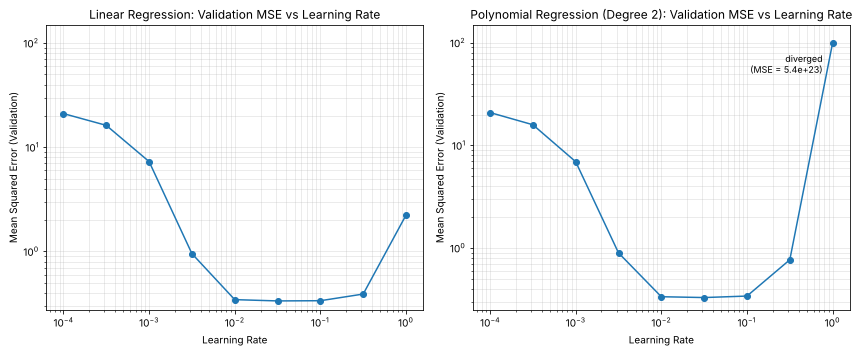

In [ ]:
# Split the data into a training set and a validation set
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# Create polynomial features for degree 2
poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train)
X_val_poly = poly.transform(X_val)

# Standardize the features (the scaler is fit on the training set only)
scaler = StandardScaler().fit(X_train)
X_train_scaled, X_val_scaled = scaler.transform(X_train), scaler.transform(X_val)
scaler_poly = StandardScaler().fit(X_train_poly)
X_train_poly_scaled, X_val_poly_scaled = scaler_poly.transform(X_train_poly), scaler_poly.transform(X_val_poly)

# 2 & 3 & 4) Test different learning rates and calculate MSE
# 9 values of the learning rate between 0.0001 and 1 (log scale)
learning_rates = np.logspace(-4, 0, 9)
n_epochs = 5  # fixed budget: 5 passes over the training data

import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)  # expected: we stop after n_epochs on purpose

linear_val_mse = []
poly_val_mse = []

for lr in learning_rates:
    # Linear regression
    linear_model = SGDRegressor(
        learning_rate='constant',
        eta0=lr,
        max_iter=n_epochs,
        tol=None,          # no early stopping: always n_epochs passes
        penalty=None,      # no regularization in this study
        random_state=42
    )

    # Train the model
    linear_model.fit(X_train_scaled, y_train)

    # Predict on validation set and calculate MSE
    y_pred = linear_model.predict(X_val_scaled)
    linear_val_mse.append(mean_squared_error(y_val, y_pred))

    # Polynomial regression (degree 2)
    poly_model = SGDRegressor(
        learning_rate='constant',
        eta0=lr,
        max_iter=n_epochs,
        tol=None,
        penalty=None,
        random_state=42
    )

    # Train the model
    poly_model.fit(X_train_poly_scaled, y_train)

    # Predict on validation set and calculate MSE
    y_pred = poly_model.predict(X_val_poly_scaled)
    poly_val_mse.append(mean_squared_error(y_val, y_pred))

# Plot the results (log scales: both axes span several orders of magnitude)
cap = 100  # errors above this value mean gradient descent diverged; they are drawn at the top edge
def plot_capped(lrs, errors):
    errors = np.array(errors)
    plt.plot(lrs, np.minimum(errors, cap), 'o-')
    for lr, e in zip(lrs, errors):
        if e > cap:
            plt.annotate(f'diverged\n(MSE = {e:.1e})', (lr, cap), textcoords='offset points',
                         xytext=(-10, -30), ha='right', fontsize=9)
    plt.xscale('log')
    plt.yscale('log')
    plt.ylim(top=cap * 1.5)

plt.figure(figsize=(12, 5))

# Linear model
plt.subplot(1, 2, 1)
plot_capped(learning_rates, linear_val_mse)
plt.title('Linear Regression: Validation MSE vs Learning Rate')
plt.xlabel('Learning Rate')
plt.ylabel('Mean Squared Error (Validation)')
plt.grid(True, which='both', alpha=0.3)

# Polynomial model
plt.subplot(1, 2, 2)
plot_capped(learning_rates, poly_val_mse)
plt.title('Polynomial Regression (Degree 2): Validation MSE vs Learning Rate')
plt.xlabel('Learning Rate')
plt.ylabel('Mean Squared Error (Validation)')
plt.grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.show()

# Print the results
print("Learning Rates and corresponding Validation MSE values:")
print("------------------------------------------------")
print("Learning Rate | Linear MSE | Polynomial MSE")
for i, lr in enumerate(learning_rates):
    print(f"{lr:13.4f} | {linear_val_mse[i]:10.4g} | {poly_val_mse[i]:.4g}")

# Find the best learning rates
best_lr_linear = learning_rates[np.argmin(linear_val_mse)]
best_lr_poly = learning_rates[np.argmin(poly_val_mse)]

print(f"\nBest learning rate for Linear Regression: {best_lr_linear:.4f}")
print(f"Best learning rate for Polynomial Regression: {best_lr_poly:.4f}")


**Reading the result:** the validation error has the U-shape of a hyperparameter study.
- **Too small** ($\alpha = 0.0001$): after 5 epochs the MSE is still about 21. Gradient descent is moving in the right direction, but has covered only a small part of the way to the minimum.
- **Good range** ($\alpha$ from 0.01 to 0.1): the MSE is about 0.33 to 0.34 for both models; the best value is $\alpha \approx 0.03$.
- **Too large**: the steps overshoot the minimum. At $\alpha = 1$ the linear model reaches an MSE of 2.2, and the polynomial model diverges.

The polynomial model becomes unstable at a smaller $\alpha$ (MSE 0.77 already at $\alpha = 0.32$): its two features, Labs and Labs², are strongly correlated, which makes the cost function steeper in one direction. A good learning rate depends on the model and the data, so it is tuned like any other hyperparameter.

----


We now train also a second degree polynomial model (linear regression with polynomial features) to illustrate tuning of the regularization parameter lambda. Both the learning rate (see above) and the regularization parameter are hyperparameters. The way to tune them is to run the model for different values of the parameters and to pick the value which results in the smallest error on the validation set. The test set is kept aside for one final estimate of performance, after all choices are made (L06). This is illustrated for the linear and for the second degree polynomial models.

Setup for the regularization study: same data, same training / validation split as above.


Training and evaluating linear models with different regularization parameters:
------------------------------------------------------------
  Lambda = 0.000100: MSE = 0.3547
  Lambda = 0.000278: MSE = 0.3548
  Lambda = 0.000774: MSE = 0.3548
  Lambda = 0.002154: MSE = 0.3551
  Lambda = 0.005995: MSE = 0.3557
  Lambda = 0.016681: MSE = 0.3574
  Lambda = 0.046416: MSE = 0.3624
  Lambda = 0.129155: MSE = 0.3777
  Lambda = 0.359381: MSE = 0.4234
  Lambda = 1.000000: MSE = 0.5302

Training and evaluating polynomial models with different regularization parameters:
------------------------------------------------------------
  Lambda = 0.000100: MSE = 0.3466
  Lambda = 0.000278: MSE = 0.3466
  Lambda = 0.000774: MSE = 0.3466
  Lambda = 0.002154: MSE = 0.3467
  Lambda = 0.005995: MSE = 0.3470
  Lambda = 0.016681: MSE = 0.3478
  Lambda = 0.046416: MSE = 0.3501
  Lambda = 0.129155: MSE = 0.3570
  Lambda = 0.359381: MSE = 0.3782
  Lambda = 1.000000: MSE = 0.4390

Regularization parameters and c

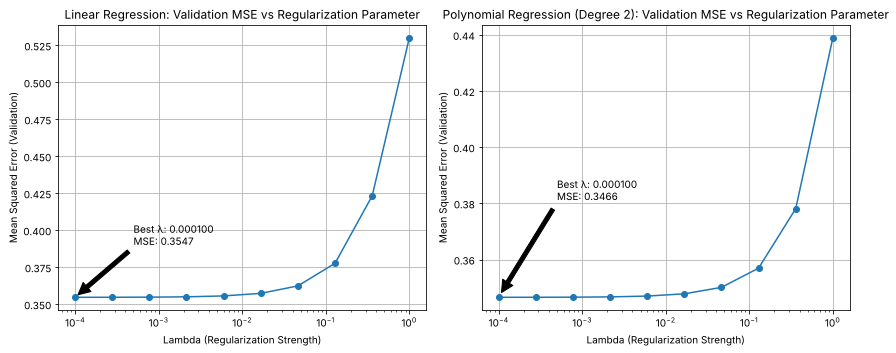

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error

# 1) Create the dataset using the provided code
data = {
    'Quizzes': [5.3, 5.5, 5.5, 5.0, 2.5, 3.0, 3.0, 3.1, 3.5, 3.5, 3.7, 4.0, 4.0, 4.0, 4.0, 5.7],
    'Labs': [5.3, 5.9, 5.29, 4.35, 5.5, 5.0, 4.0, 3.1, 4.5, 5.62, 5.0, 3.0, 4.0, 5.75, 4.44, 5.9],
    'Final': [4.818, 5.773, 4.464, 5.069, 4.164, 4.091, 3.727, 3.909, 3.518, 4.897, 5.209, 3.0, 3.091, 5.818, 4.069, 5.77]
}

# Convert to DataFrame
df = pd.DataFrame(data)

# Augmenting data by replicating and adding noise
np.random.seed(42)
augmented = []
for i in range(len(df)):
    row = df.iloc[i]
    for _ in range(10):  # Create 10 variations of each record
        noise = np.random.normal(0, 0.2, 3)  # Add Gaussian noise with mean=0 and std=0.2
        new_row = row + noise
        # Ensure values are within boundaries (grades must be between 2 and 6)
        new_row = new_row.clip(2, 6)
        augmented.append(new_row)

# Create augmented DataFrame
df_aug = pd.DataFrame(augmented, columns=df.columns)

# Extract the features we want to use: Labs vs Final
X = df_aug['Labs'].values.reshape(-1, 1)
y = df_aug['Final'].values

# Split the data into a training set and a validation set
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# Create polynomial features for degree 2
poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train)
X_val_poly = poly.transform(X_val)

# Standardize features for better convergence
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

# For polynomial features, scale after transformation
scaler_poly = StandardScaler()
X_train_poly_scaled = scaler_poly.fit_transform(X_train_poly)
X_val_poly_scaled = scaler_poly.transform(X_val_poly)

# 2, 3 & 4) Test different regularization parameters and calculate MSE
# Create 10 values of Lambda (regularization parameter) between 0.0001 and 1.0 (log scale)
Lambdas = np.logspace(-4, 0, 10)  # 10 values between 0.0001 and 1.0 on log scale

# Fixed learning rate, in the good range of the sweep above
learning_rate = 0.01

# Initialize arrays to store results
linear_val_mse = []
poly_val_mse = []

print("\nTraining and evaluating linear models with different regularization parameters:")
print("-" * 60)

for Lambda in Lambdas:
    # Linear regression
    try:
        linear_model = SGDRegressor(
            alpha=Lambda,  # Regularization parameter (alpha in sklearn)
            learning_rate='constant',
            eta0=learning_rate,
            max_iter=1000,
            tol=1e-3,
            random_state=42,
            penalty='l2'  # L2 regularization (Ridge)
        )

        # Train the model on scaled data
        linear_model.fit(X_train_scaled, y_train)

        # Predict on scaled validation set
        y_pred = linear_model.predict(X_val_scaled)

        # Calculate MSE
        mse = mean_squared_error(y_val, y_pred)

        print(f"  Lambda = {Lambda:.6f}: MSE = {mse:.4f}")
        linear_val_mse.append(mse)

    except Exception as e:
        print(f"  Error with Lambda {Lambda:.6f}: {e}")
        linear_val_mse.append(None)

print("\nTraining and evaluating polynomial models with different regularization parameters:")
print("-" * 60)

for Lambda in Lambdas:
    # Polynomial regression
    try:
        poly_model = SGDRegressor(
            alpha=Lambda,  # Regularization parameter (alpha in sklearn)
            learning_rate='constant',
            eta0=learning_rate,
            max_iter=1000,
            tol=1e-3,
            random_state=42,
            penalty='l2'  # L2 regularization (Ridge)
        )

        # Train the model on scaled data
        poly_model.fit(X_train_poly_scaled, y_train)

        # Predict on scaled validation set
        y_pred = poly_model.predict(X_val_poly_scaled)

        # Calculate MSE
        mse = mean_squared_error(y_val, y_pred)

        print(f"  Lambda = {Lambda:.6f}: MSE = {mse:.4f}")
        poly_val_mse.append(mse)

    except Exception as e:
        print(f"  Error with Lambda {Lambda:.6f}: {e}")
        poly_val_mse.append(None)

# Filter out None values for plotting
valid_linear_data = [(L, mse) for L, mse in zip(Lambdas, linear_val_mse) if mse is not None]
valid_poly_data = [(L, mse) for L, mse in zip(Lambdas, poly_val_mse) if mse is not None]

# Plot the results
plt.figure(figsize=(12, 5))

# Linear model
plt.subplot(1, 2, 1)
if valid_linear_data:
    valid_Lambdas, valid_mses = zip(*valid_linear_data)
    plt.plot(valid_Lambdas, valid_mses, 'o-')
    plt.xscale('log')  # Log scale for Lambda values
    plt.title('Linear Regression: Validation MSE vs Regularization Parameter')
    plt.xlabel('Lambda (Regularization Strength)')
    plt.ylabel('Mean Squared Error (Validation)')
    plt.grid(True)

    # Annotate the best Lambda
    min_idx = np.argmin(valid_mses)
    plt.annotate(f'Best λ: {valid_Lambdas[min_idx]:.6f}\nMSE: {valid_mses[min_idx]:.4f}',
                xy=(valid_Lambdas[min_idx], valid_mses[min_idx]),
                xytext=(valid_Lambdas[min_idx]*5, valid_mses[min_idx]*1.1),
                arrowprops=dict(facecolor='black', shrink=0.05))
else:
    plt.text(0.5, 0.5, 'No valid results', ha='center', va='center')

# Polynomial model
plt.subplot(1, 2, 2)
if valid_poly_data:
    valid_Lambdas, valid_mses = zip(*valid_poly_data)
    plt.plot(valid_Lambdas, valid_mses, 'o-')
    plt.xscale('log')  # Log scale for Lambda values
    plt.title('Polynomial Regression (Degree 2): Validation MSE vs Regularization Parameter')
    plt.xlabel('Lambda (Regularization Strength)')
    plt.ylabel('Mean Squared Error (Validation)')
    plt.grid(True)

    #  best Lambda
    min_idx = np.argmin(valid_mses)
    plt.annotate(f'Best λ: {valid_Lambdas[min_idx]:.6f}\nMSE: {valid_mses[min_idx]:.4f}',
                xy=(valid_Lambdas[min_idx], valid_mses[min_idx]),
                xytext=(valid_Lambdas[min_idx]*5, valid_mses[min_idx]*1.1),
                arrowprops=dict(facecolor='black', shrink=0.05))
else:
    plt.text(0.5, 0.5, 'No valid results', ha='center', va='center')

plt.tight_layout()
plt.show()

# results table
print("\nRegularization parameters and corresponding Validation MSE values:")
print("-" * 60)
print("Lambda        | Linear MSE     | Polynomial MSE")
print("-" * 60)
for i, Lambda in enumerate(Lambdas):
    linear_mse = "Invalid" if linear_val_mse[i] is None else f"{linear_val_mse[i]:.4f}"
    poly_mse = "Invalid" if poly_val_mse[i] is None else f"{poly_val_mse[i]:.4f}"
    print(f"{Lambda:.6f}    | {linear_mse.ljust(14)} | {poly_mse}")

# Find the best Lambdas from valid data
if valid_linear_data:
    best_Lambda_linear = valid_linear_data[np.argmin([mse for _, mse in valid_linear_data])][0]
    best_mse_linear = min([mse for _, mse in valid_linear_data])
    print(f"\nBest Lambda for Linear Regression: {best_Lambda_linear:.6f} (MSE: {best_mse_linear:.4f})")
else:
    print("\nNo valid results for Linear Regression")

if valid_poly_data:
    best_Lambda_poly = valid_poly_data[np.argmin([mse for _, mse in valid_poly_data])][0]
    best_mse_poly = min([mse for _, mse in valid_poly_data])
    print(f"Best Lambda for Polynomial Regression: {best_Lambda_poly:.6f} (MSE: {best_mse_poly:.4f})")
else:
    print("No valid results for Polynomial Regression")

**Reading the result:** compare the validation error across $\lambda$. Here it is smallest at (or very close to) the smallest $\lambda$ and grows for large $\lambda$. A degree-2 model trained on 128 samples has low variance, so the penalty mainly adds bias (L05: a larger $\lambda$ increases bias and decreases variance). Regularization pays off for flexible models trained on few data, such as the degree-9 polynomial of the bias-variance notebook.

We now train the models (linear and polynomial degree 2) with the best reg. parameter (lambda), and provide visualizations.

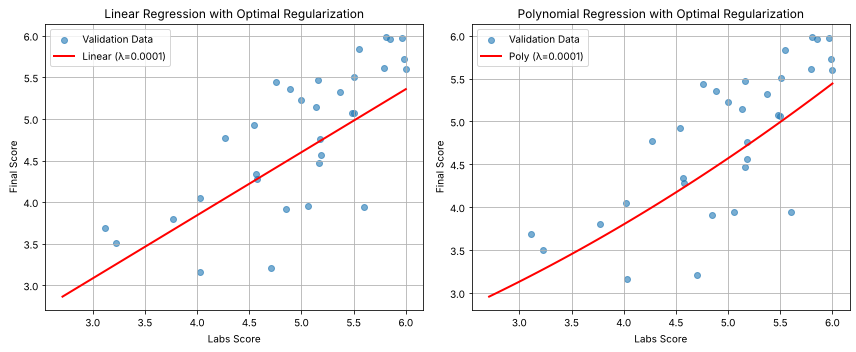

In [ ]:
# Train final models with the best Lambdas
if valid_linear_data and valid_poly_data:
    # Linear model with best Lambda
    best_linear_model = SGDRegressor(
        alpha=best_Lambda_linear,
        learning_rate='constant',
        eta0=learning_rate,
        max_iter=1000,
        tol=1e-3,
        random_state=42,
        penalty='l2'
    )
    best_linear_model.fit(X_train_scaled, y_train)

    # Polynomial model with best Lambda
    best_poly_model = SGDRegressor(
        alpha=best_Lambda_poly,
        learning_rate='constant',
        eta0=learning_rate,
        max_iter=1000,
        tol=1e-3,
        random_state=42,
        penalty='l2'
    )
    best_poly_model.fit(X_train_poly_scaled, y_train)

    # Create a range of X values for plotting
    X_range = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
    X_range_scaled = scaler.transform(X_range)
    X_range_poly = poly.transform(X_range)
    X_range_poly_scaled = scaler_poly.transform(X_range_poly)

    # Predict with the optimal models
    y_range_linear = best_linear_model.predict(X_range_scaled)
    y_range_poly = best_poly_model.predict(X_range_poly_scaled)

    # Plot the fitted models
    plt.figure(figsize=(12, 5))

    # Linear model
    plt.subplot(1, 2, 1)
    plt.scatter(X_val, y_val, alpha=0.6, label='Validation Data')
    plt.plot(X_range, y_range_linear, 'r-', linewidth=2, label=f'Linear (λ={best_Lambda_linear:.4f})')
    plt.title('Linear Regression with Optimal Regularization')
    plt.xlabel('Labs Score')
    plt.ylabel('Final Score')
    plt.legend()
    plt.grid(True)

    # Polynomial model
    plt.subplot(1, 2, 2)
    plt.scatter(X_val, y_val, alpha=0.6, label='Validation Data')
    plt.plot(X_range, y_range_poly, 'r-', linewidth=2, label=f'Poly (λ={best_Lambda_poly:.4f})')
    plt.title('Polynomial Regression with Optimal Regularization')
    plt.xlabel('Labs Score')
    plt.ylabel('Final Score')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

# Learning curves

Now we load our data, but we augment it more than before (we create for each "original" data point 100 more points, instead of 10 as before).

We need more data to demonstrate what happens with the prediction accuracy when we train with more data. The plot of the model performance as a function of training set size is called "Learning curve". The training set grows from 5 to 1280 samples; the validation set stays fixed. We will again use the linear model and the polynomial model of degree 2.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error

# Create the dataset using the provided code
data = {
    'Quizzes': [5.3, 5.5, 5.5, 5.0, 2.5, 3.0, 3.0, 3.1, 3.5, 3.5, 3.7, 4.0, 4.0, 4.0, 4.0, 5.7],
    'Labs': [5.3, 5.9, 5.29, 4.35, 5.5, 5.0, 4.0, 3.1, 4.5, 5.62, 5.0, 3.0, 4.0, 5.75, 4.44, 5.9],
    'Final': [4.818, 5.773, 4.464, 5.069, 4.164, 4.091, 3.727, 3.909, 3.518, 4.897, 5.209, 3.0, 3.091, 5.818, 4.069, 5.77]
}

# Convert to DataFrame
df = pd.DataFrame(data)

# Augmenting data by replicating and adding noise - now 100 variations per original point
np.random.seed(42)
augmented = []
for i in range(len(df)):
    row = df.iloc[i]
    for _ in range(100):  # Create 100 variations of each record (before we had 10)
        noise = np.random.normal(0, 0.2, 3)  # Add Gaussian noise with mean=0 and std=0.2
        new_row = row + noise
        # Ensure values are within boundaries (grades must be between 2 and 6)
        new_row = new_row.clip(2, 6)
        augmented.append(new_row)

# Create augmented DataFrame
df_aug = pd.DataFrame(augmented, columns=df.columns)

# Extract the features we want to use: Labs vs Final
X = df_aug['Labs'].values.reshape(-1, 1)
y = df_aug['Final'].values

The fixed validation set for the learning-curve study, and the polynomial features of degree 2. The validation set stays identical across all training-set sizes, so the curves remain comparable.

In [ ]:
# Split the data into a training set and a validation set (always the same validation set).
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# Create polynomial features for degree 2
poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train)
X_val_poly = poly.transform(X_val)

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

scaler_poly = StandardScaler()
X_train_poly_scaled = scaler_poly.fit_transform(X_train_poly)
X_val_poly_scaled = scaler_poly.transform(X_val_poly)

# Function to compute learning curves with absolute training sizes
def plot_learning_curve(model_name, X_train, y_train, X_val, y_val):
    # Absolute training set sizes, doubling from 5 samples up to the full training set
    train_sizes = np.array([5, 10, 20, 40, 80, 160, 320, 640, len(X_train)])

    # Storage for training and validation errors
    train_errors = []
    val_errors = []

    # Set model parameters based on previous findings
    if model_name == 'linear':
        model = SGDRegressor(
            alpha=0.01,            # Regularization parameter (small, see the lambda study above)
            learning_rate='constant',
            eta0=0.01,             # Learning rate
            max_iter=1000,
            random_state=42
        )
        X_train_data = X_train_scaled
        X_val_data = X_val_scaled
    else:  # polynomial
        model = SGDRegressor(
            alpha=0.01,            # Regularization parameter (small, see the lambda study above)
            learning_rate='constant',
            eta0=0.01,             # Learning rate
            max_iter=1000,
            random_state=42
        )
        X_train_data = X_train_poly_scaled
        X_val_data = X_val_poly_scaled

    # For each absolute training set size
    for n_samples in train_sizes:
        # Train the model on a subset of the training data
        model.fit(X_train_data[:n_samples], y_train[:n_samples])

        # Calculate training error
        y_train_pred = model.predict(X_train_data[:n_samples])
        train_error = mean_squared_error(y_train[:n_samples], y_train_pred)
        train_errors.append(train_error)

        # Calculate validation error (always on the full validation set)
        y_val_pred = model.predict(X_val_data)
        val_error = mean_squared_error(y_val, y_val_pred)
        val_errors.append(val_error)

    return train_sizes, train_errors, val_errors

We will now check how adding more data affects the model performance, always using the same validation set.


Learning Curve Data
--------------------------------------------------------------------------------
Training Set  |  Linear Model                |  Polynomial Model
Size          |  Train Error    Val Error    |  Train Error    Val Error
--------------------------------------------------------------------------------
   5          |  0.2369        0.4255    |  0.1959        0.4038
  10          |  0.2903        0.4235    |  0.2616        0.3979
  20          |  0.3591        0.4247    |  0.3269        0.4041
  40          |  0.3531        0.4269    |  0.3130        0.4180
  80          |  0.3769        0.4089    |  0.3434        0.3911
 160          |  0.3855        0.3793    |  0.3648        0.3682
 320          |  0.4057        0.3768    |  0.3909        0.3661
 640          |  0.3857        0.3764    |  0.3684        0.3634
1280          |  0.3817        0.3834    |  0.3583        0.3610

Learning Curve Analysis:
------------------------------
Linear Model:
  Final train-validatio

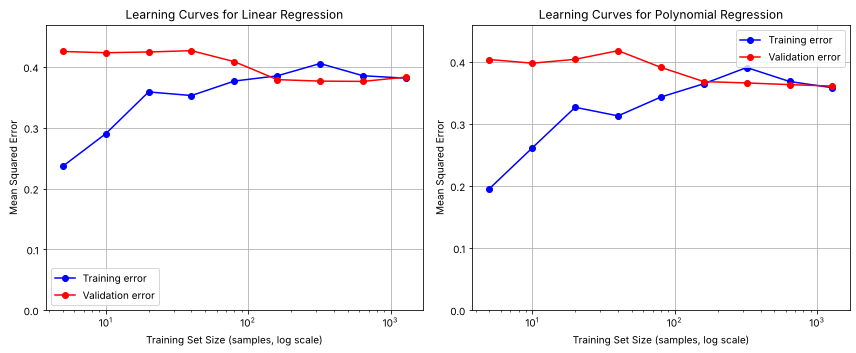

In [ ]:
# Generate learning curves for both models
linear_sizes, linear_train_errors, linear_val_errors = plot_learning_curve(
    'linear', X_train, y_train, X_val, y_val
)

poly_sizes, poly_train_errors, poly_val_errors = plot_learning_curve(
    'polynomial', X_train, y_train, X_val, y_val
)

# Plot learning curves with absolute training set size
plt.figure(figsize=(12, 5))

# Linear model learning curve
plt.subplot(1, 2, 1)
plt.plot(linear_sizes, linear_train_errors, 'o-', color='blue', label='Training error')
plt.plot(linear_sizes, linear_val_errors, 'o-', color='red', label='Validation error')
plt.title('Learning Curves for Linear Regression')
plt.xscale('log')
plt.xlabel('Training Set Size (samples, log scale)')
plt.ylabel('Mean Squared Error')
plt.legend()
plt.grid(True)
plt.ylim(0, max(max(linear_train_errors), max(linear_val_errors))*1.1)

# Polynomial model learning curve
plt.subplot(1, 2, 2)
plt.plot(poly_sizes, poly_train_errors, 'o-', color='blue', label='Training error')
plt.plot(poly_sizes, poly_val_errors, 'o-', color='red', label='Validation error')
plt.title('Learning Curves for Polynomial Regression')
plt.xscale('log')
plt.xlabel('Training Set Size (samples, log scale)')
plt.ylabel('Mean Squared Error')
plt.legend()
plt.grid(True)
plt.ylim(0, max(max(poly_train_errors), max(poly_val_errors))*1.1)

plt.tight_layout()
plt.show()

# Print the learning curve data in tabular format
print("\nLearning Curve Data")
print("-" * 80)
print("Training Set  |  Linear Model                |  Polynomial Model")
print("Size          |  Train Error    Val Error    |  Train Error    Val Error")
print("-" * 80)

for i, size in enumerate(linear_sizes):
    print(f"{size:4d}          |  {linear_train_errors[i]:.4f}        {linear_val_errors[i]:.4f}    |  {poly_train_errors[i]:.4f}        {poly_val_errors[i]:.4f}")

# Analyze the learning curves
print("\nLearning Curve Analysis:")
print("-" * 30)

# For Linear Model
final_gap_linear = abs(linear_train_errors[-1] - linear_val_errors[-1])
train_improvement_linear = linear_train_errors[0] - linear_train_errors[-1]
val_improvement_linear = linear_val_errors[0] - linear_val_errors[-1]

print(f"Linear Model:")
print(f"  Final train-validation gap: {final_gap_linear:.4f}")
print(f"  Training error improved by: {train_improvement_linear:.4f}")
print(f"  Validation error improved by: {val_improvement_linear:.4f}")

# For Polynomial Model
final_gap_poly = abs(poly_train_errors[-1] - poly_val_errors[-1])
train_improvement_poly = poly_train_errors[0] - poly_train_errors[-1]
val_improvement_poly = poly_val_errors[0] - poly_val_errors[-1]

print(f"\nPolynomial Model:")
print(f"  Final train-validation gap: {final_gap_poly:.4f}")
print(f"  Training error improved by: {train_improvement_poly:.4f}")
print(f"  Validation error improved by: {val_improvement_poly:.4f}")

# Print information about dataset sizes
print(f"\nTotal dataset size after augmentation: {len(df_aug)} samples")
print(f"Training set size: {len(X_train)} samples")
print(f"Validation set size: {len(X_val)} samples")

Now we will test the performance of different *algorithms*, the same way as we tune hyperparameters. We will run the algorithms (assuming the hyperparameters for each of them are already tuned) and will pick the one with the best performance. We will compare linear regression, polynomial regression of high degree, and neural network.

Also, the data are split in training, validation, and test. Cross-validation on the training data (5 folds, each used once as the validation set, L06) compares the three algorithms; the algorithm with the smallest validation error is selected. The test set is used once, at the end, to evaluate the selected algorithm. Most of the code below can be skipped, the important part is understanding the plot.


**Reading the result:** the two curves behave as described in the lecture.
- **Few samples:** with 5 training samples the training error is small (0.24 linear, 0.20 polynomial) and the validation error is large (0.43 and 0.40): the model fits the few points it has seen and generalizes poorly. The negative "Training error improved by" values in the printout mean that the training error *increased* with more data, as expected.
- **More samples:** the gap closes at about 160 samples. From there on, both errors stay at about 0.36 to 0.38, and more data no longer helps.
- **Diagnosis:** a small gap with an error that stops falling points to **bias**. Collecting more data will not reduce it; a more informative model will, for example adding the quiz score as a second feature. The polynomial model reaches a slightly lower level (0.361 vs 0.383) because its curve has more flexibility.

Evaluating Linear Regression...
  Train MSE: 0.3408, Val MSE: 0.3648, Test MSE: 0.3454
  Train R²: 0.5938, Val R²: 0.5420, Test R²: 0.5053
Evaluating Polynomial (degree 9)...
  Train MSE: 0.3101, Val MSE: 0.3372, Test MSE: 0.3372
  Train R²: 0.6304, Val R²: 0.5773, Test R²: 0.5169
Evaluating Neural Network...
  Train MSE: 0.3533, Val MSE: 0.3628, Test MSE: 0.3777
  Train R²: 0.5789, Val R²: 0.5443, Test R²: 0.4590

Model Performance Summary:
Model                  Train MSE   Val MSE     Test MSE    Train R²    Val R²      Test R²     
-----------------------------------------------------------------------------------
Linear Regression      0.3408      0.3648      0.3454      0.5938      0.5420      0.5053      
Polynomial (degree 9)  0.3101      0.3372      0.3372      0.6304      0.5773      0.5169      
Neural Network         0.3533      0.3628      0.3777      0.5789      0.5443      0.4590      

Selected by validation MSE: Polynomial (degree 9)
Its test MSE (final estimate): 0.33

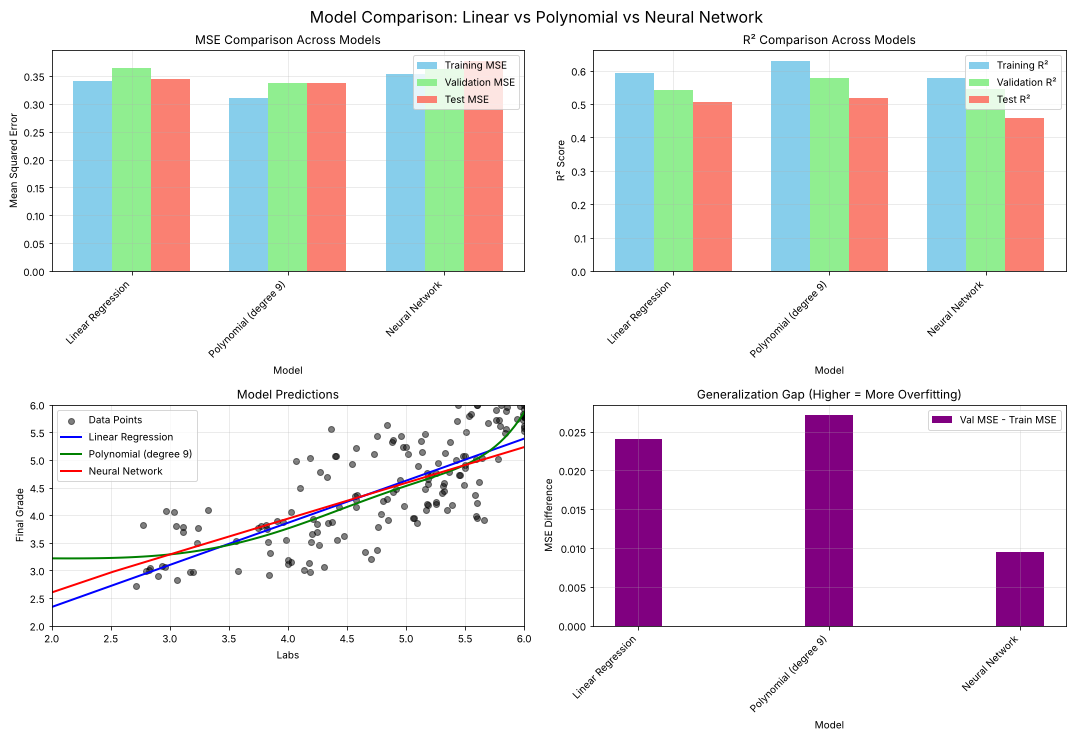

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, KFold
from sklearn.pipeline import make_pipeline
import warnings

# Suppress warnings
warnings.filterwarnings("ignore")

# Define the data from the provided code
data = {
    'Quizzes': [5.3, 5.5, 5.5, 5.0, 2.5, 3.0, 3.0, 3.1, 3.5, 3.5, 3.7, 4.0, 4.0, 4.0, 4.0, 5.7],
    'Labs': [5.3, 5.9, 5.29, 4.35, 5.5, 5.0, 4.0, 3.1, 4.5, 5.62, 5.0, 3.0, 4.0, 5.75, 4.44, 5.9],
    'Final': [4.818, 5.773, 4.464, 5.069, 4.164, 4.091, 3.727, 3.909, 3.518, 4.897, 5.209, 3.0, 3.091, 5.818, 4.069, 5.77]
}

# Convert to DataFrame
df = pd.DataFrame(data)

# Augmenting data by replicating and adding noise
np.random.seed(42)
augmented = []
for i in range(len(df)):
    row = df.iloc[i]
    for _ in range(10):  # Create 10 variations of each record
        noise = np.random.normal(0, 0.2, 3)  # Add Gaussian noise with mean=0 and std=0.2
        new_row = row + noise
        # Ensure values are within boundaries (grades must be between 2 and 6)
        new_row = new_row.clip(2, 6)
        augmented.append(new_row)

# Create augmented DataFrame
df_aug = pd.DataFrame(augmented, columns=df.columns)

def compare_models(df_aug, n_splits=5, test_size=0.2, random_state=42):
    """
    Compare different regression models:
    1. Linear Regression
    2. 9th Degree Polynomial Regression
    3. Simple Neural Network

    Parameters:
    - df_aug: Augmented DataFrame
    - n_splits: Number of cross-validation splits
    - test_size: Proportion of data for final testing
    - random_state: Random seed for reproducibility

    Returns:
    - Performance metrics for each model
    """
    # Use Labs as the feature and Final as the target
    X = df_aug[['Labs']]
    y = df_aug['Final']

    # Split data into train+val and test sets (note that this is a two-stage splitting, later (few lines below) we have the second stage.
    X_trainval, X_test, y_trainval, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )

    # Define models
    models = {
        'Linear Regression': make_pipeline(LinearRegression()),
        'Polynomial (degree 9)': make_pipeline(PolynomialFeatures(degree=9), LinearRegression()),
        'Neural Network': MLPRegressor(
            hidden_layer_sizes=(10, 5),  # Simple architecture with 2 hidden layers
            max_iter=1000,
            activation='relu',
            solver='adam',
            alpha=0.0001,  # Regularization parameter
            random_state=random_state
        )
    }

    # Prepare cross-validation (for now ignore this, later in the notebook cross-validation is illustrated).
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)

    # Results storage
    results = {
        'model_names': [],
        'train_mse': [],
        'val_mse': [],
        'test_mse': [],
        'train_r2': [],
        'val_r2': [],
        'test_r2': []
    }

    # For visualization
    x_grid = np.linspace(2, 6, 100).reshape(-1, 1)
    prediction_curves = {}

    # Train and evaluate each model
    for name, model in models.items():
        print(f"Evaluating {name}...")

        # Cross-validation
        cv_train_mse = []
        cv_val_mse = []
        cv_train_r2 = []
        cv_val_r2 = []

        for train_idx, val_idx in kf.split(X_trainval):
            # Split data
            X_train, X_val = X_trainval.iloc[train_idx], X_trainval.iloc[val_idx]
            y_train, y_val = y_trainval.iloc[train_idx], y_trainval.iloc[val_idx]

            # Train model
            model.fit(X_train, y_train)

            # Predictions
            y_train_pred = model.predict(X_train)
            y_val_pred = model.predict(X_val)

            # Metrics
            train_mse = mean_squared_error(y_train, y_train_pred)
            val_mse = mean_squared_error(y_val, y_val_pred)
            train_r2 = r2_score(y_train, y_train_pred)
            val_r2 = r2_score(y_val, y_val_pred)

            # Store CV results
            cv_train_mse.append(train_mse)
            cv_val_mse.append(val_mse)
            cv_train_r2.append(train_r2)
            cv_val_r2.append(val_r2)

        # Retrain on full training+validation set
        model.fit(X_trainval, y_trainval)

        # Test predictions
        y_test_pred = model.predict(X_test)
        test_mse = mean_squared_error(y_test, y_test_pred)
        test_r2 = r2_score(y_test, y_test_pred)

        # Store average results
        results['model_names'].append(name)
        results['train_mse'].append(np.mean(cv_train_mse))
        results['val_mse'].append(np.mean(cv_val_mse))
        results['test_mse'].append(test_mse)
        results['train_r2'].append(np.mean(cv_train_r2))
        results['val_r2'].append(np.mean(cv_val_r2))
        results['test_r2'].append(test_r2)

        # Generate prediction curve for visualization
        prediction_curves[name] = model.predict(x_grid)

        print(f"  Train MSE: {np.mean(cv_train_mse):.4f}, Val MSE: {np.mean(cv_val_mse):.4f}, Test MSE: {test_mse:.4f}")
        print(f"  Train R²: {np.mean(cv_train_r2):.4f}, Val R²: {np.mean(cv_val_r2):.4f}, Test R²: {test_r2:.4f}")

    # Create visualizations
    # 1. MSE Comparison
    plt.figure(figsize=(15, 10))

    plt.subplot(2, 2, 1)
    bar_width = 0.25
    index = np.arange(len(results['model_names']))

    plt.bar(index - bar_width, results['train_mse'], bar_width, label='Training MSE', color='skyblue')
    plt.bar(index, results['val_mse'], bar_width, label='Validation MSE', color='lightgreen')
    plt.bar(index + bar_width, results['test_mse'], bar_width, label='Test MSE', color='salmon')

    plt.xlabel('Model')
    plt.ylabel('Mean Squared Error')
    plt.title('MSE Comparison Across Models')
    plt.xticks(index, results['model_names'], rotation=45, ha='right')
    plt.legend()
    plt.grid(True, alpha=0.3)

    # 2. R² Comparison
    plt.subplot(2, 2, 2)

    plt.bar(index - bar_width, results['train_r2'], bar_width, label='Training R²', color='skyblue')
    plt.bar(index, results['val_r2'], bar_width, label='Validation R²', color='lightgreen')
    plt.bar(index + bar_width, results['test_r2'], bar_width, label='Test R²', color='salmon')

    plt.xlabel('Model')
    plt.ylabel('R² Score')
    plt.title('R² Comparison Across Models')
    plt.xticks(index, results['model_names'], rotation=45, ha='right')
    plt.legend()
    plt.grid(True, alpha=0.3)

    # 3. Prediction Curves
    plt.subplot(2, 2, 3)

    # Plot the original data
    plt.scatter(X, y, color='black', alpha=0.5, label='Data Points')

    # Plot prediction curves
    colors = ['blue', 'green', 'red']
    for i, (name, curve) in enumerate(prediction_curves.items()):
        plt.plot(x_grid, curve, color=colors[i], linewidth=2, label=name)

    plt.xlabel('Labs')
    plt.ylabel('Final Grade')
    plt.title('Model Predictions')
    plt.xlim(2, 6)
    plt.ylim(2, 6)
    plt.legend()
    plt.grid(True, alpha=0.3)

    # 4. Generalization gap
    plt.subplot(2, 2, 4)

    # Difference between validation and training error (both averaged over the CV folds)
    train_val_diff = [val - train for train, val in zip(results['train_mse'], results['val_mse'])]

    # A large gap is a sign of overfitting (high variance)
    plt.bar(index, train_val_diff, bar_width, label='Val MSE - Train MSE', color='purple')

    plt.xlabel('Model')
    plt.ylabel('MSE Difference')
    plt.title('Generalization Gap (Higher = More Overfitting)')
    plt.xticks(index, results['model_names'], rotation=45, ha='right')
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.suptitle('Model Comparison: Linear vs Polynomial vs Neural Network', fontsize=16, y=1.02)

    return plt.gcf(), results, prediction_curves

# Run the model comparison
fig, results, prediction_curves = compare_models(df_aug)

# Display and save results
plt.savefig('model_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

# Print summary table
print("\nModel Performance Summary:")
print("=" * 83)
print(f"{'Model':<23}{'Train MSE':<12}{'Val MSE':<12}{'Test MSE':<12}{'Train R²':<12}{'Val R²':<12}{'Test R²':<12}")
print("-" * 83)
for i, model in enumerate(results['model_names']):
    print(f"{model:<23}{results['train_mse'][i]:<12.4f}{results['val_mse'][i]:<12.4f}{results['test_mse'][i]:<12.4f}"
          f"{results['train_r2'][i]:<12.4f}{results['val_r2'][i]:<12.4f}{results['test_r2'][i]:<12.4f}")

# Model selection uses the validation error; the test error is reported once for the selected model
best = int(np.argmin(results['val_mse']))
print(f"\nSelected by validation MSE: {results['model_names'][best]}")
print(f"Its test MSE (final estimate): {results['test_mse'][best]:.4f}")


# Accuracy, precision, recall, F-score #


We will now move to performance metrics for classification. We will use the logistic regression model as a classification algorithm.

We will illustrate the concept of applying threshold to the probility outputs.

Setup for the classification metrics: pass means a final grade above 4.5, and the lab average is the single feature. (The Week 5 notebook used a final grade above 4.0 as pass.) A student is predicted to pass when $\hat{y} > \tau$, as in the lecture.

Model coefficients: 2.0011
Model intercept: -9.9306
Decision boundary (p=0.5) at Lab score = 4.9627
Best accuracy threshold: 0.38 (accuracy 0.792)
Best F1 threshold: 0.38 (F1 0.821)


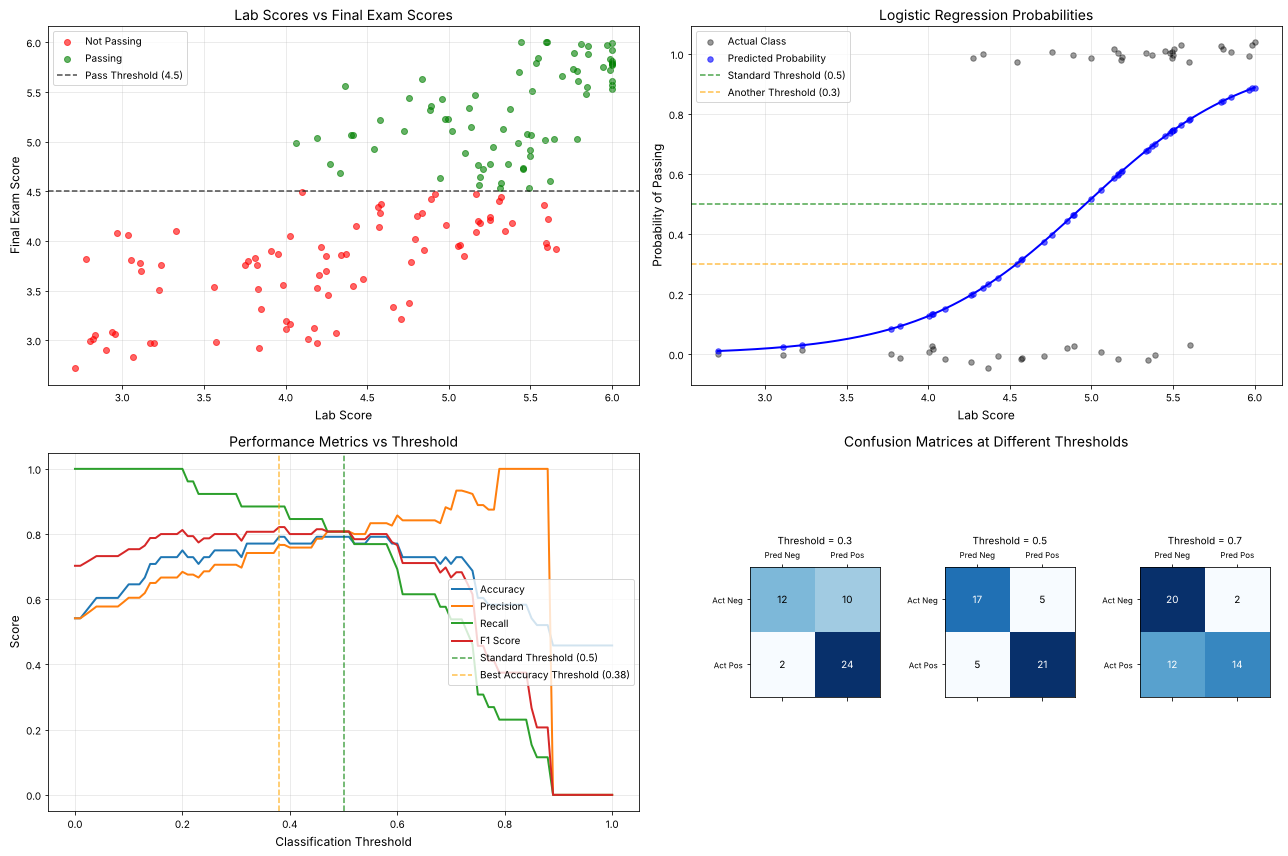

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split

# Initial data
data = {
    'Quizzes': [5.3, 5.5, 5.5, 5.0, 2.5, 3.0, 3.0, 3.1, 3.5, 3.5, 3.7, 4.0, 4.0, 4.0, 4.0, 5.7],
    'Labs': [5.3, 5.9, 5.29, 4.35, 5.5, 5.0, 4.0, 3.1, 4.5, 5.62, 5.0, 3.0, 4.0, 5.75, 4.44, 5.9],
    'Final': [4.818, 5.773, 4.464, 5.069, 4.164, 4.091, 3.727, 3.909, 3.518, 4.897, 5.209, 3.0, 3.091, 5.818, 4.069, 5.77]
}

# Convert to DataFrame
df = pd.DataFrame(data)

# Augmenting data by replicating and adding noise
np.random.seed(42)
augmented = []
for i in range(len(df)):
    row = df.iloc[i]
    for _ in range(10):  # Create 10 variations of each record
        noise = np.random.normal(0, 0.2, 3)  # Add Gaussian noise with mean=0 and std=0.2
        new_row = row + noise
        # Ensure values are within boundaries (grades must be between 2 and 6)
        new_row = new_row.clip(2, 6)
        augmented.append(new_row)

# Create augmented DataFrame
df_aug = pd.DataFrame(augmented, columns=df.columns)

# For logistic regression, we need a categorical target
# Above 4.5 = "Pass" (1), Below 4.5 = "Needs Improvement" (0)
df_aug['Pass'] = (df_aug['Final'] > 4.5).astype(int)

# Use only 'Labs' to predict 'Pass'
X = df_aug[['Labs']]
y = df_aug['Pass']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Train logistic regression model
model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)

# Get predicted probabilities
y_pred_prob = model.predict_proba(X_test)[:, 1]

# Create a range of thresholds
thresholds = np.linspace(0, 1, 101)  # From 0 to 1 in steps of 0.01

# Calculate metrics for each threshold
accuracy_scores = []
precision_scores = []
recall_scores = []
f1_scores = []
confusion_matrices = []

for threshold in thresholds:
    y_pred = (y_pred_prob > threshold).astype(int)
    accuracy_scores.append(accuracy_score(y_test, y_pred))
    precision_scores.append(precision_score(y_test, y_pred, zero_division=0))
    recall_scores.append(recall_score(y_test, y_pred, zero_division=0))
    f1_scores.append(f1_score(y_test, y_pred, zero_division=0))
    confusion_matrices.append(confusion_matrix(y_test, y_pred))

# Find the threshold with the highest accuracy
best_accuracy_idx = np.argmax(accuracy_scores)
best_accuracy_threshold = thresholds[best_accuracy_idx]
best_accuracy = accuracy_scores[best_accuracy_idx]

# Find the threshold with the highest F1 score
best_f1_idx = np.argmax(f1_scores)
best_f1_threshold = thresholds[best_f1_idx]
best_f1 = f1_scores[best_f1_idx]

# Create a figure with subplots
fig = plt.figure(figsize=(18, 12))

# First plot: Labs vs Final with color coding for passing/not passing
ax1 = fig.add_subplot(2, 2, 1)
ax1.scatter(df_aug[df_aug['Pass'] == 0]['Labs'],
           df_aug[df_aug['Pass'] == 0]['Final'],
           color='red', alpha=0.6, label='Not Passing')
ax1.scatter(df_aug[df_aug['Pass'] == 1]['Labs'],
           df_aug[df_aug['Pass'] == 1]['Final'],
           color='green', alpha=0.6, label='Passing')
ax1.axhline(y=4.5, color='black', linestyle='--', alpha=0.7, label='Pass Threshold (4.5)')
ax1.set_xlabel('Lab Score', fontsize=12)
ax1.set_ylabel('Final Exam Score', fontsize=12)
ax1.set_title('Lab Scores vs Final Exam Scores', fontsize=14)
ax1.grid(True, alpha=0.3)
ax1.legend()

# Second plot: Logistic Regression Probabilities
ax2 = fig.add_subplot(2, 2, 2)

# Sort the test data by Lab scores for smoother plotting
sorted_indices = np.argsort(X_test['Labs'].values)
sorted_labs = X_test['Labs'].values[sorted_indices]
sorted_probs = y_pred_prob[sorted_indices]
sorted_actuals = y_test.values[sorted_indices]

# Plot the actual class with jitter for visibility
jitter = np.random.default_rng(0).normal(0, 0.02, len(sorted_actuals))
ax2.scatter(sorted_labs, sorted_actuals + jitter, color='black', alpha=0.4, s=30, label='Actual Class')

# Plot the predicted probabilities
ax2.scatter(sorted_labs, sorted_probs, color='blue', alpha=0.6, s=30, label='Predicted Probability')

# Add example thresholds
ax2.axhline(y=0.5, color='green', linestyle='--', alpha=0.7, label='Standard Threshold (0.5)')
ax2.axhline(y=0.3, color='orange', linestyle='--', alpha=0.7,
           label=f'Another Threshold (0.3)')

# Create a continuous prediction curve
lab_range = pd.DataFrame({'Labs': np.linspace(min(sorted_labs), max(sorted_labs), 300)})
prob_range = model.predict_proba(lab_range)[:, 1]
ax2.plot(lab_range, prob_range, color='blue', linewidth=2)

ax2.set_xlabel('Lab Score', fontsize=12)
ax2.set_ylabel('Probability of Passing', fontsize=12)
ax2.set_title('Logistic Regression Probabilities', fontsize=14)
ax2.grid(True, alpha=0.3)
ax2.legend()

# Third plot: Accuracy, Precision, Recall vs Threshold
ax3 = fig.add_subplot(2, 2, 3)
ax3.plot(thresholds, accuracy_scores, label='Accuracy', linewidth=2)
ax3.plot(thresholds, precision_scores, label='Precision', linewidth=2)
ax3.plot(thresholds, recall_scores, label='Recall', linewidth=2)
ax3.plot(thresholds, f1_scores, label='F1 Score', linewidth=2)
ax3.axvline(x=0.5, color='green', linestyle='--', alpha=0.7, label='Standard Threshold (0.5)')
ax3.axvline(x=best_accuracy_threshold, color='orange', linestyle='--', alpha=0.7,
           label=f'Best Accuracy Threshold ({best_accuracy_threshold:.2f})')

ax3.set_xlabel('Classification Threshold', fontsize=12)
ax3.set_ylabel('Score', fontsize=12)
ax3.set_title('Performance Metrics vs Threshold', fontsize=14)
ax3.grid(True, alpha=0.3)
ax3.legend(loc='center right')

# Fourth plot: Confusion matrices at different thresholds
ax4 = fig.add_subplot(2, 2, 4)

# Choose several thresholds to show confusion matrices
example_thresholds = [0.3, 0.5, 0.7]
colors = ['lightblue', 'lightgreen', 'lightsalmon']

for k, threshold in enumerate(example_thresholds):
    idx = np.abs(thresholds - threshold).argmin()  # Find the closest threshold
    cm = confusion_matrices[idx]

    # A mini confusion matrix inside the fourth panel, side by side
    mini_ax = ax4.inset_axes([0.10 + k*0.33, 0.25, 0.22, 0.5])
    mini_ax.matshow(cm, cmap='Blues')
    mini_ax.set_title(f'Threshold = {threshold:.1f}', fontsize=10)
    mini_ax.set_xticks([0, 1])
    mini_ax.set_yticks([0, 1])
    mini_ax.set_xticklabels(['Pred Neg', 'Pred Pos'], fontsize=8)
    mini_ax.set_yticklabels(['Act Neg', 'Act Pos'], fontsize=8)

    # Add the confusion matrix values
    for i in range(2):
        for j in range(2):
            mini_ax.text(j, i, str(cm[i, j]),
                       ha="center", va="center", fontsize=10,
                       color="white" if cm[i, j] > cm.max()/2 else "black")

ax4.axis('off')
ax4.set_title('Confusion Matrices at Different Thresholds', fontsize=14)

plt.tight_layout()
plt.savefig('threshold_effects_on_accuracy.png', dpi=300)
plt.show()

# Print summary information
print(f"Model coefficients: {model.coef_[0][0]:.4f}")
print(f"Model intercept: {model.intercept_[0]:.4f}")
print(f"Decision boundary (p=0.5) at Lab score = {(-model.intercept_[0]/model.coef_[0][0]):.4f}")
print(f"Best accuracy threshold: {best_accuracy_threshold:.2f} (accuracy {best_accuracy:.3f})")
print(f"Best F1 threshold: {best_f1_threshold:.2f} (F1 {best_f1:.3f})")


The sigmoid fit and the decision boundary at $\tau = 0.5$.

Performance metrics at different thresholds:

Threshold | Accuracy | Precision | Recall | F1 Score | TN | FP | FN | TP
---------------------------------------------------------------------------
     0.25 |    0.729 |     0.686 |  0.923 |    0.787 | 11 | 11 |  2 | 24
     0.30 |    0.750 |     0.706 |  0.923 |    0.800 | 12 | 10 |  2 | 24
     0.50 |    0.792 |     0.808 |  0.808 |    0.808 | 17 |  5 |  5 | 21
     0.75 |    0.604 |     0.889 |  0.308 |    0.457 | 21 |  1 | 18 |  8
     0.95 |    0.458 |     0.000 |  0.000 |    0.000 | 22 |  0 | 26 |  0

Logistic Regression Model:
P(Pass) = 1 / (1 + exp(-(-9.931 + 2.001 * Lab)))
Decision boundary (p=0.5) at Lab score = 4.963

Class distribution in test set:
Pass rate: 54.2%
Fail rate: 45.8%


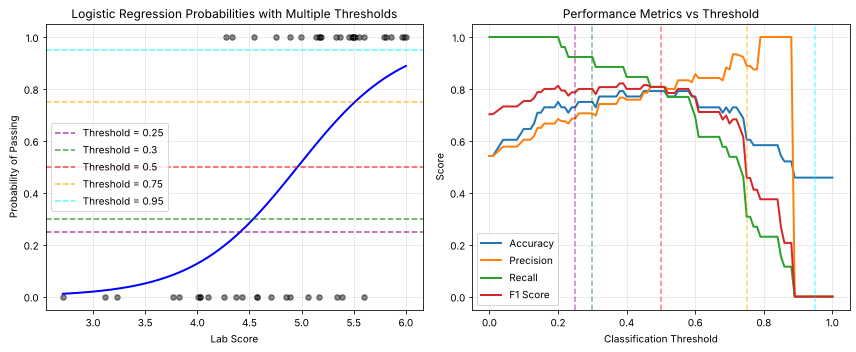

In [ ]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Train logistic regression model
model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)

# Get predicted probabilities
y_pred_prob = model.predict_proba(X_test)[:, 1]

# Create a range of thresholds to evaluate
thresholds = np.linspace(0, 1, 101)  # From 0 to 1 in steps of 0.01

# Calculate metrics for each threshold
accuracy_scores = []
precision_scores = []
recall_scores = []
f1_scores = []
confusion_matrices = []

for threshold in thresholds:
    y_pred = (y_pred_prob > threshold).astype(int)
    accuracy_scores.append(accuracy_score(y_test, y_pred))
    precision_scores.append(precision_score(y_test, y_pred, zero_division=0))
    recall_scores.append(recall_score(y_test, y_pred, zero_division=0))
    f1_scores.append(f1_score(y_test, y_pred, zero_division=0))
    confusion_matrices.append(confusion_matrix(y_test, y_pred))

# Specific thresholds requested
specific_thresholds = [0.25, 0.3, 0.5, 0.75, 0.95]
specific_indices = [np.abs(thresholds - t).argmin() for t in specific_thresholds]

# Create the visualization with only two subplots
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Sort the test data by Lab scores for plotting
sorted_indices = np.argsort(X_test['Labs'].values)
sorted_labs = X_test['Labs'].values[sorted_indices]
sorted_probs = y_pred_prob[sorted_indices]
sorted_actuals = y_test.values[sorted_indices]

# Create a continuous prediction curve
lab_range = np.linspace(min(X['Labs']), max(X['Labs']), 300).reshape(-1, 1)
lab_range_df = pd.DataFrame(lab_range, columns=['Labs'])
prob_range = model.predict_proba(lab_range_df)[:, 1]

# Plot 1: Lab scores vs Probability with multiple thresholds
axs[0].scatter(X_test['Labs'], y_test, c='black', alpha=0.5, s=30)
axs[0].plot(lab_range, prob_range, color='blue', linewidth=2)

# Add the specific thresholds
colors = ['purple', 'green', 'red', 'orange', 'cyan']
for i, threshold in enumerate(specific_thresholds):
    axs[0].axhline(y=threshold, color=colors[i], linestyle='--', alpha=0.7,
                   label=f'Threshold = {threshold}')

axs[0].set_xlabel('Lab Score')
axs[0].set_ylabel('Probability of Passing')
axs[0].set_title('Logistic Regression Probabilities with Multiple Thresholds')
axs[0].grid(True, alpha=0.3)
axs[0].legend()

# Plot 2: Metrics vs Threshold with specific thresholds marked
axs[1].plot(thresholds, accuracy_scores, label='Accuracy', linewidth=2)
axs[1].plot(thresholds, precision_scores, label='Precision', linewidth=2)
axs[1].plot(thresholds, recall_scores, label='Recall', linewidth=2)
axs[1].plot(thresholds, f1_scores, label='F1 Score', linewidth=2)

# Mark specific thresholds on the metrics plot
for i, (threshold, idx) in enumerate(zip(specific_thresholds, specific_indices)):
    axs[1].axvline(x=threshold, color=colors[i], linestyle='--', alpha=0.5)

axs[1].set_xlabel('Classification Threshold')
axs[1].set_ylabel('Score')
axs[1].set_title('Performance Metrics vs Threshold')
axs[1].grid(True, alpha=0.3)
axs[1].legend()

plt.tight_layout()
plt.savefig('two_subplots_threshold_analysis.png', dpi=300)
plt.show()

# Print metrics for each threshold
print("Performance metrics at different thresholds:\n")
print("Threshold | Accuracy | Precision | Recall | F1 Score | TN | FP | FN | TP")
print("-" * 75)

for threshold, idx in zip(specific_thresholds, specific_indices):
    cm = confusion_matrices[idx]
    tn, fp, fn, tp = cm.ravel()

    print(f"{threshold:9.2f} | {accuracy_scores[idx]:8.3f} | {precision_scores[idx]:9.3f} | {recall_scores[idx]:6.3f} | {f1_scores[idx]:8.3f} | {tn:2d} | {fp:2d} | {fn:2d} | {tp:2d}")

# Print the decision boundary (Lab score where p=0.5)
decision_boundary = -model.intercept_[0]/model.coef_[0][0]
print(f"\nLogistic Regression Model:")
print(f"P(Pass) = 1 / (1 + exp(-({model.intercept_[0]:.3f} + {model.coef_[0][0]:.3f} * Lab)))")
print(f"Decision boundary (p=0.5) at Lab score = {decision_boundary:.3f}")

# Calculate class distribution
pass_rate = y_test.mean() * 100
print(f"\nClass distribution in test set:")
print(f"Pass rate: {pass_rate:.1f}%")
print(f"Fail rate: {100-pass_rate:.1f}%")

The same model evaluated at several thresholds: the confusion matrix moves with $\tau$, and every metric built from it moves along.

Performance metrics at different thresholds:

Threshold | Accuracy | Precision | Recall | F1 Score | TN | FP | FN | TP
---------------------------------------------------------------------------
     0.25 |    0.729 |     0.686 |  0.923 |    0.787 | 11 | 11 |  2 | 24
     0.30 |    0.750 |     0.706 |  0.923 |    0.800 | 12 | 10 |  2 | 24
     0.50 |    0.792 |     0.808 |  0.808 |    0.808 | 17 |  5 |  5 | 21
     0.75 |    0.604 |     0.889 |  0.308 |    0.457 | 21 |  1 | 18 |  8
     0.95 |    0.458 |     0.000 |  0.000 |    0.000 | 22 |  0 | 26 |  0

Logistic Regression Model:
P(Pass) = 1 / (1 + exp(-(-9.931 + 2.001 * Lab)))
Decision boundary (p=0.5) at Lab score = 4.963

Class distribution in test set:
Pass rate: 54.2%
Fail rate: 45.8%


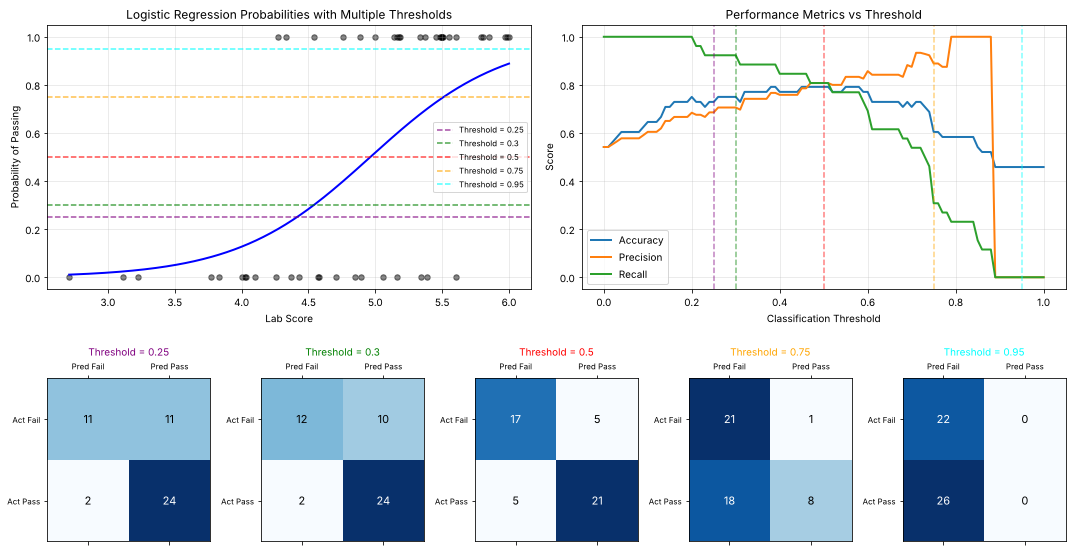

In [ ]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Train logistic regression model
model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)

# Get predicted probabilities
y_pred_prob = model.predict_proba(X_test)[:, 1]

# Create a range of thresholds to evaluate
thresholds = np.linspace(0, 1, 101)  # From 0 to 1 in steps of 0.01

# Calculate metrics for each threshold
accuracy_scores = []
precision_scores = []
recall_scores = []
f1_scores = []
confusion_matrices = []

for threshold in thresholds:
    y_pred = (y_pred_prob > threshold).astype(int)
    accuracy_scores.append(accuracy_score(y_test, y_pred))
    precision_scores.append(precision_score(y_test, y_pred, zero_division=0))
    recall_scores.append(recall_score(y_test, y_pred, zero_division=0))
    f1_scores.append(f1_score(y_test, y_pred, zero_division=0))
    confusion_matrices.append(confusion_matrix(y_test, y_pred))

# Specific thresholds requested
specific_thresholds = [0.25, 0.3, 0.5, 0.75, 0.95]
specific_indices = [np.abs(thresholds - t).argmin() for t in specific_thresholds]

# Create the visualization: curves on top, one confusion matrix per threshold below
fig = plt.figure(figsize=(15, 8))
gs = fig.add_gridspec(2, 10, height_ratios=[1.3, 1])
ax_prob = fig.add_subplot(gs[0, :5])
ax_met = fig.add_subplot(gs[0, 5:])

# Create a continuous prediction curve
lab_range = pd.DataFrame({'Labs': np.linspace(min(X['Labs']), max(X['Labs']), 300)})
prob_range = model.predict_proba(lab_range)[:, 1]

colors = ['purple', 'green', 'red', 'orange', 'cyan']

# Plot 1: Lab scores vs Probability with multiple thresholds
ax_prob.scatter(X_test['Labs'], y_test, c='black', alpha=0.5, s=30)
ax_prob.plot(lab_range['Labs'], prob_range, color='blue', linewidth=2)
for i, threshold in enumerate(specific_thresholds):
    ax_prob.axhline(y=threshold, color=colors[i], linestyle='--', alpha=0.7, label=f'Threshold = {threshold}')
ax_prob.set_xlabel('Lab Score')
ax_prob.set_ylabel('Probability of Passing')
ax_prob.set_title('Logistic Regression Probabilities with Multiple Thresholds')
ax_prob.grid(True, alpha=0.3)
ax_prob.legend(fontsize=8)

# Plot 2: Metrics vs Threshold with specific thresholds marked
ax_met.plot(thresholds, accuracy_scores, label='Accuracy', linewidth=2)
ax_met.plot(thresholds, precision_scores, label='Precision', linewidth=2)
ax_met.plot(thresholds, recall_scores, label='Recall', linewidth=2)
for i, threshold in enumerate(specific_thresholds):
    ax_met.axvline(x=threshold, color=colors[i], linestyle='--', alpha=0.5)
ax_met.set_xlabel('Classification Threshold')
ax_met.set_ylabel('Score')
ax_met.set_title('Performance Metrics vs Threshold')
ax_met.grid(True, alpha=0.3)
ax_met.legend()

# Row 2: confusion matrix at each threshold
for i, (threshold, idx) in enumerate(zip(specific_thresholds, specific_indices)):
    ax = fig.add_subplot(gs[1, 2*i:2*i+2])
    cm = confusion_matrices[idx]
    ax.matshow(cm, cmap='Blues')
    for r in range(2):
        for c in range(2):
            ax.text(c, r, str(cm[r, c]), ha='center', va='center', fontsize=11,
                    color='white' if cm[r, c] > cm.max()/2 else 'black')
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(['Pred Fail', 'Pred Pass'], fontsize=8)
    ax.set_yticklabels(['Act Fail', 'Act Pass'], fontsize=8)
    ax.set_title(f'Threshold = {threshold}', color=colors[i], fontsize=10)

plt.tight_layout()
plt.show()

# Print metrics for each threshold
print("Performance metrics at different thresholds:\n")
print("Threshold | Accuracy | Precision | Recall | F1 Score | TN | FP | FN | TP")
print("-" * 75)

for threshold, idx in zip(specific_thresholds, specific_indices):
    cm = confusion_matrices[idx]
    tn, fp, fn, tp = cm.ravel()

    print(f"{threshold:9.2f} | {accuracy_scores[idx]:8.3f} | {precision_scores[idx]:9.3f} | {recall_scores[idx]:6.3f} | {f1_scores[idx]:8.3f} | {tn:2d} | {fp:2d} | {fn:2d} | {tp:2d}")

# Print the decision boundary (Lab score where p=0.5)
decision_boundary = -model.intercept_[0]/model.coef_[0][0]
print(f"\nLogistic Regression Model:")
print(f"P(Pass) = 1 / (1 + exp(-({model.intercept_[0]:.3f} + {model.coef_[0][0]:.3f} * Lab)))")
print(f"Decision boundary (p=0.5) at Lab score = {decision_boundary:.3f}")

# Calculate class distribution
pass_rate = y_test.mean() * 100
print(f"\nClass distribution in test set:")
print(f"Pass rate: {pass_rate:.1f}%")
print(f"Fail rate: {100-pass_rate:.1f}%")

We now plot the precision-recall curve

Precision and Recall at different thresholds:
Threshold | Precision | Recall  | TP | FP | TN | FN
--------------------------------------------------
     0.25 |     0.686 |   0.923 | 24 | 11 | 11 |  2
     0.50 |     0.808 |   0.808 | 21 |  5 | 17 |  5
     0.75 |     0.889 |   0.308 |  8 |  1 | 21 | 18


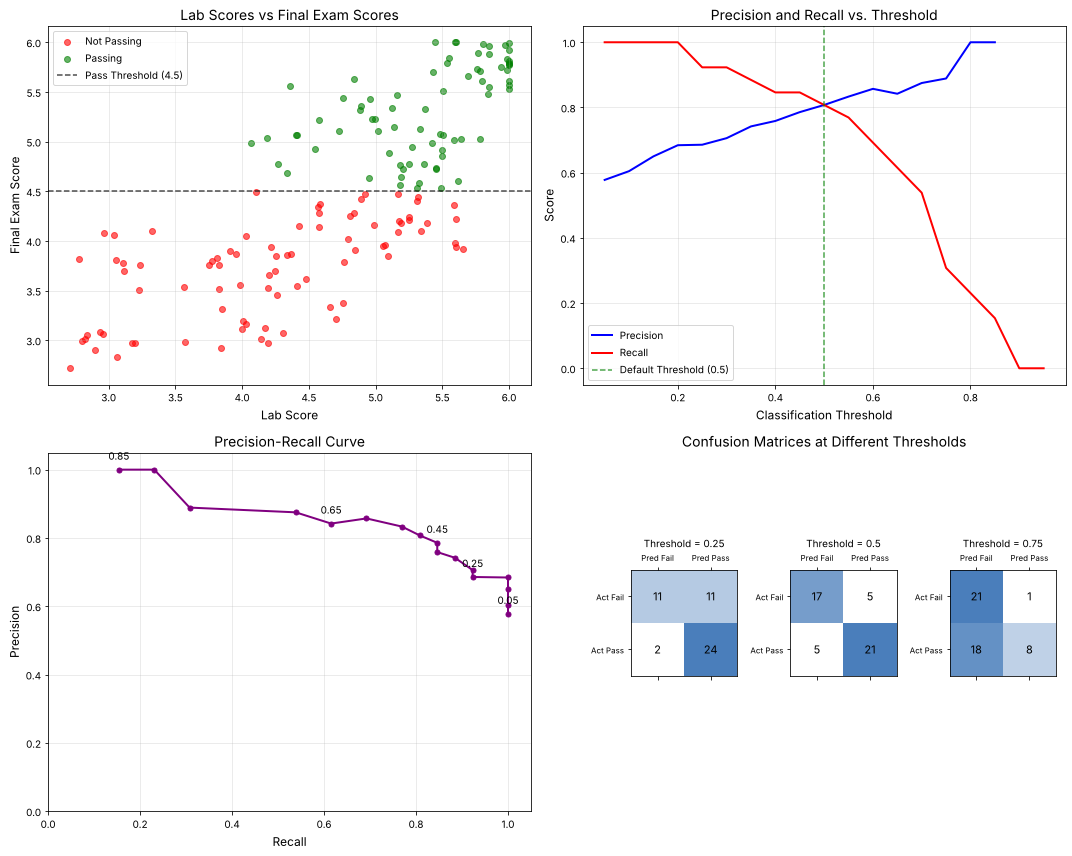

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

# Train logistic regression model
model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)

# Get predicted probabilities
y_pred_prob = model.predict_proba(X_test)[:, 1]

# Create a range of thresholds to evaluate
thresholds = np.linspace( 0.05, 0.95, 19)  # From 0.05 to 0.95 in steps of 0.05

# Calculate precision and recall for each threshold
precision_scores = []
recall_scores = []
confusion_matrices = []

for threshold in thresholds:
    y_pred = (y_pred_prob > threshold).astype(int)
    # Precision is undefined when no student is predicted to pass: store NaN (not plotted)
    precision_scores.append(precision_score(y_test, y_pred) if y_pred.sum() > 0 else np.nan)
    recall_scores.append(recall_score(y_test, y_pred))
    confusion_matrices.append(confusion_matrix(y_test, y_pred))

# Create a figure with multiple plots
plt.figure(figsize=(15, 12))

# Plot 1: Scatter plot of Labs vs Final with color coding
ax1 = plt.subplot(2, 2, 1)
ax1.scatter(df_aug[df_aug['Pass'] == 0]['Labs'], df_aug[df_aug['Pass'] == 0]['Final'],
            color='red', alpha=0.6, label='Not Passing')
ax1.scatter(df_aug[df_aug['Pass'] == 1]['Labs'], df_aug[df_aug['Pass'] == 1]['Final'],
            color='green', alpha=0.6, label='Passing')
ax1.axhline(y=4.5, color='black', linestyle='--', alpha=0.7, label='Pass Threshold (4.5)')
ax1.set_xlabel('Lab Score', fontsize=12)
ax1.set_ylabel('Final Exam Score', fontsize=12)
ax1.set_title('Lab Scores vs Final Exam Scores', fontsize=14)
ax1.grid(True, alpha=0.3)
ax1.legend()

# Plot 2: Precision and Recall vs Threshold
ax2 = plt.subplot(2, 2, 2)
ax2.plot(thresholds, precision_scores, 'b-', linewidth=2, label='Precision')
ax2.plot(thresholds, recall_scores, 'r-', linewidth=2, label='Recall')
ax2.axvline(x=0.5, color='green', linestyle='--', alpha=0.7, label='Default Threshold (0.5)')
ax2.set_xlabel('Classification Threshold', fontsize=12)
ax2.set_ylabel('Score', fontsize=12)
ax2.set_title('Precision and Recall vs. Threshold', fontsize=14)
ax2.grid(True, alpha=0.3)
ax2.legend()

# Plot 3: Precision-Recall Curve
ax3 = plt.subplot(2, 2, 3)
ax3.plot(recall_scores, precision_scores, 'purple', marker='o', markersize=5, linewidth=2)

# Add threshold annotations to a few points
for i, threshold in enumerate(thresholds):
    if i % 4 == 0 and not np.isnan(precision_scores[i]):  # Only annotate every 4th point to avoid clutter
        ax3.annotate(f'{threshold:.2f}',
                    (recall_scores[i], precision_scores[i]),
                    textcoords="offset points",
                    xytext=(0,10),
                    ha='center')

ax3.set_xlabel('Recall', fontsize=12)
ax3.set_ylabel('Precision', fontsize=12)
ax3.set_title('Precision-Recall Curve', fontsize=14)
ax3.grid(True, alpha=0.3)
ax3.set_xlim(0, 1.05)
ax3.set_ylim(0, 1.05)

# Plot 4: Confusion Matrices at different thresholds
ax4 = plt.subplot(2, 2, 4)
ax4.axis('off')

# Define a custom colormap (blue gradient)
cmap = LinearSegmentedColormap.from_list('blue_gradient', ['white', '#4a7ebb'])

# Choose specific thresholds to show confusion matrices
example_thresholds = [0.25, 0.5, 0.75]
positions = [(0.10, 0.3), (0.43, 0.3), (0.76, 0.3)]  # Positions (inside the fourth panel) for the confusion matrices

for threshold, (px, py) in zip(example_thresholds, positions):
    cm = confusion_matrices[np.abs(thresholds - threshold).argmin()]
    mini_ax = ax4.inset_axes([px, py, 0.22, 0.45])
    mini_ax.matshow(cm, cmap=cmap)
    for r in range(2):
        for c in range(2):
            mini_ax.text(c, r, str(cm[r, c]), ha='center', va='center', fontsize=11)
    mini_ax.set_xticks([0, 1]); mini_ax.set_yticks([0, 1])
    mini_ax.set_xticklabels(['Pred Fail', 'Pred Pass'], fontsize=8)
    mini_ax.set_yticklabels(['Act Fail', 'Act Pass'], fontsize=8)
    mini_ax.set_title(f'Threshold = {threshold}', fontsize=10)
ax4.set_title('Confusion Matrices at Different Thresholds', fontsize=14)

plt.tight_layout()
plt.savefig('precision_recall_explanation.png', dpi=300)
plt.show()

# Calculate and print some example values for specific thresholds
print("Precision and Recall at different thresholds:")
print("Threshold | Precision | Recall  | TP | FP | TN | FN")
print("-" * 50)

for threshold in [0.25, 0.5, 0.75]:
    idx = np.abs(thresholds - threshold).argmin()
    tn, fp, fn, tp = confusion_matrices[idx].ravel()
    precision = precision_scores[idx]
    recall = recall_scores[idx]
    print(f"{threshold:9.2f} | {precision:9.3f} | {recall:7.3f} | {tp:2d} | {fp:2d} | {tn:2d} | {fn:2d}")

We will now switch the dataset to illustrate the precision-recall curve with a better-behaved dataset. The learning task is to classify benign vs malignant tumors, given 30 measurements of the cell nuclei in a tissue sample (radius, texture, area, and others).

Note on the labels: in scikit-learn's version of this dataset, class 1 is **benign** and class 0 is malignant. The positive class below is therefore "benign", and the no-skill line sits at the fraction of benign tumors in the test set.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score, precision_recall_curve, average_precision_score
from sklearn.preprocessing import StandardScaler
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap

# Load the breast cancer dataset (binary classification)
data = load_breast_cancer()
X = data.data
y = data.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Scale the features (the scaler is fit on the training set only)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Precision-recall on the cancer dataset: the model, the curve, and the no-skill line at the positive rate of the test set.

Precision range: 0.6316 to 1.0000
Recall range: 0.0000 to 1.0000
Set axis limits - X: 0.00 to 1.05, Y: 0.58 to 1.05
Optimal point - Precision: 0.9907, Recall: 0.9907


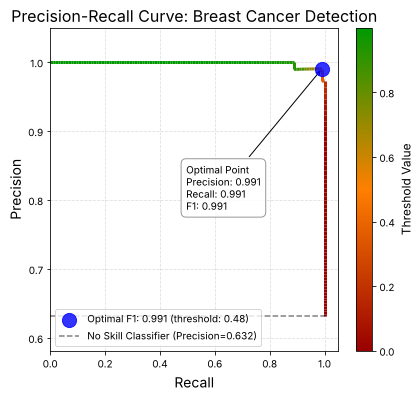

In [ ]:
# Train logistic regression model
model = LogisticRegression(random_state=42, max_iter=1000)
model.fit(X_train, y_train)

# Get predicted probabilities
y_pred_prob = model.predict_proba(X_test)[:, 1]

# Calculate precision-recall curve
precision, recall, thresholds = precision_recall_curve(y_test, y_pred_prob)

# Calculate F1 scores for each threshold
f1_scores = []
for i in range(len(thresholds)):
    f1 = 2 * (precision[i] * recall[i]) / (precision[i] + recall[i]) if (precision[i] + recall[i]) > 0 else 0
    f1_scores.append(f1)

# Find the threshold with the best F1 score
best_f1_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_f1_idx]
best_precision = precision[best_f1_idx]
best_recall = recall[best_f1_idx]
best_f1 = f1_scores[best_f1_idx]

# average precision score
average_precision = average_precision_score(y_test, y_pred_prob)

min_precision = np.min(precision)
min_recall = np.min(recall)

# axis limits
x_min = max(0, min_recall - 0.05)
y_min = max(0, min_precision - 0.05)


plt.figure(figsize=(6, 6))

# gradient-colored line for the precision-recall curve
points = np.array([recall, precision]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)

# colormap
colors = [(0.6, 0, 0), (1, 0.5, 0), (0, 0.6, 0)]  # Red -> Orange -> Green
cmap = LinearSegmentedColormap.from_list('custom_cmap', colors)

# Normalize the thresholds to use for coloring
norm = plt.Normalize(thresholds.min(), thresholds.max())
lc = LineCollection(segments, cmap=cmap, norm=norm)
lc.set_array(thresholds)
lc.set_linewidth(3)
line = plt.gca().add_collection(lc)

cbar = plt.colorbar(line, ax=plt.gca())
cbar.set_label('Threshold Value', fontsize=12)

# point with the best F1 score
plt.scatter([best_recall], [best_precision], c='blue', s=200, zorder=10, alpha=0.8,
           label=f'Optimal F1: {best_f1:.3f} (threshold: {best_threshold:.2f})')

# optimal point
plt.annotate(f'Optimal Point\nPrecision: {best_precision:.3f}\nRecall: {best_recall:.3f}\nF1: {best_f1:.3f}',
             xy=(best_recall, best_precision),
             xytext=(best_recall-(best_recall-x_min)/2, best_precision-(best_precision-y_min)/2),
             arrowprops=dict(arrowstyle="->", connectionstyle="arc3", color='black'),
             bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="gray", alpha=0.8),
             fontsize=10)

# Add a dashed line for the no-skill classifier
plt.plot([0, 1], [y_test.mean(), y_test.mean()], 'k--', alpha=0.5,
         label=f'No Skill Classifier (Precision={y_test.mean():.3f})')

# Add formatting
plt.title('Precision-Recall Curve: Breast Cancer Detection', fontsize=16)
plt.xlabel('Recall', fontsize=14)
plt.ylabel('Precision', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.4)

# Set better axis limits
plt.xlim([x_min, 1.05])
plt.ylim([y_min, 1.05])

# Find better positions for explanatory text based on actual data distribution
high_precision_x = x_min + (1 - x_min) * 0.2
high_precision_y = 0.95
high_recall_x = 0.85
high_recall_y = y_min + (1 - y_min) * 0.3


#plt.text(high_precision_x, high_precision_y, 'High Precision Region\nFewer false positives', fontsize=10,
#        bbox=dict(boxstyle="round,pad=0.5", fc="lightblue", ec="blue", alpha=0.6))
#plt.text(high_recall_x, high_recall_y, 'High Recall Region\nFewer false negatives', fontsize=10,
#        bbox=dict(boxstyle="round,pad=0.5", fc="lightyellow", ec="orange", alpha=0.6))


#plt.figtext(0.5, 0.01,
#           f"Breast Cancer Wisconsin Dataset: Binary classification task: benign (positive, 1) vs malignant (negative, 0) tumors.\n"
#           f"Average Precision Score: {average_precision:.3f}",
#           wrap=True, horizontalalignment='center', fontsize=12)

# Add legend
plt.legend(loc='lower left', fontsize=10)

plt.tight_layout(rect=[0, 0.03, 1, 0.97])
plt.savefig('improved_breast_cancer_pr_curve.png', dpi=300, bbox_inches='tight')

# Print information about the actual data range
print(f"Precision range: {min_precision:.4f} to {np.max(precision):.4f}")
print(f"Recall range: {min_recall:.4f} to {np.max(recall):.4f}")
print(f"Set axis limits - X: {x_min:.2f} to 1.05, Y: {y_min:.2f} to 1.05")
print(f"Optimal point - Precision: {best_precision:.4f}, Recall: {best_recall:.4f}")

# Splitting datasets: fixed split, $K$-fold cross-validation, leave-one-out cross-validation #

Setup for the data-splitting comparison: fixed split, $K$-fold cross-validation, and leave-one-out.

Logistic Regression Model Evaluation Results
--------------------------------------------------------------------------------
             Method  Accuracy Precision Recall F1 Score Std Dev (Accuracy)  Execution Time (s)
Fixed Split (70/30)    0.7917    0.8077 0.8077   0.8077                N/A              0.0194
       K-Fold (K=5)    0.7812    0.7457 0.8177   0.7780             0.0342              0.1690
      Leave-One-Out    0.7875       N/A    N/A      N/A                N/A              1.3976

Detailed K-Fold Cross-Validation Results:
------------------------------------------------------------
 Fold  Accuracy  Precision  Recall  F1 Score
    1    0.7812     0.8421  0.8000    0.8205
    2    0.7812     0.6667  0.8333    0.7407
    3    0.8125     0.7500  0.8571    0.8000
    4    0.8125     0.7857  0.7857    0.7857
    5    0.7188     0.6842  0.8125    0.7429
------------------------------------------------------------
Mean Accuracy: 0.7812 (±0.0342)
Mean Precision: 0.7457 (±0.

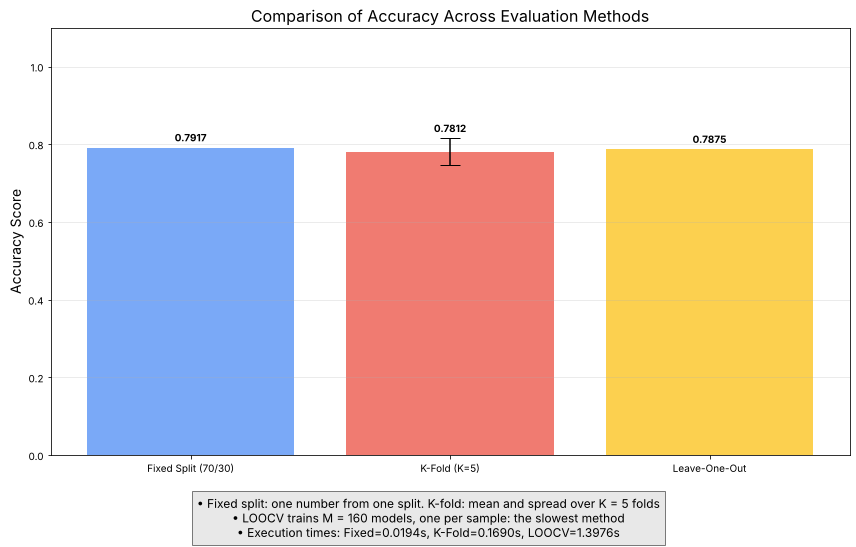

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, KFold, LeaveOneOut, cross_val_score, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler
import time

# Set random seed for reproducibility
np.random.seed(42)

# Initial data
data = {
    'Quizzes': [5.3, 5.5, 5.5, 5.0, 2.5, 3.0, 3.0, 3.1, 3.5, 3.5, 3.7, 4.0, 4.0, 4.0, 4.0, 5.7],
    'Labs': [5.3, 5.9, 5.29, 4.35, 5.5, 5.0, 4.0, 3.1, 4.5, 5.62, 5.0, 3.0, 4.0, 5.75, 4.44, 5.9],
    'Final': [4.818, 5.773, 4.464, 5.069, 4.164, 4.091, 3.727, 3.909, 3.518, 4.897, 5.209, 3.0, 3.091, 5.818, 4.069, 5.77]
}

# Convert to DataFrame
df = pd.DataFrame(data)

# Augmenting data by replicating and adding noise
augmented = []
for i in range(len(df)):
    row = df.iloc[i]
    for _ in range(10):  # Create 10 variations of each record
        noise = np.random.normal(0, 0.2, 3)  # Add Gaussian noise with mean=0 and std=0.2
        new_row = row + noise
        # Ensure values are within boundaries (grades must be between 2 and 6)
        new_row = new_row.clip(2, 6)
        augmented.append(new_row)

# Create augmented DataFrame
df_aug = pd.DataFrame(augmented, columns=df.columns)

# For logistic regression, we need a categorical target
# Above 4.5 = "Pass" (1), Below 4.5 = "Needs Improvement" (0)
df_aug['Pass'] = (df_aug['Final'] > 4.5).astype(int)

# Use only 'Labs' to predict 'Pass'
X = df_aug[['Labs']]
y = df_aug['Pass']

# Model: scaling + logistic regression in one pipeline, so that the scaler is
# fit on the training part of every split only (the held-out data never influence it)
model = make_pipeline(StandardScaler(), LogisticRegression(random_state=42))
X_scaled = X  # the pipeline scales internally

# 1. Fixed Split Evaluation
start_time = time.time()
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

fixed_accuracy = accuracy_score(y_test, y_pred)
fixed_precision = precision_score(y_test, y_pred)
fixed_recall = recall_score(y_test, y_pred)
fixed_f1 = f1_score(y_test, y_pred)
fixed_time = time.time() - start_time

# 2. K-Fold Cross-Validation (K=5)
start_time = time.time()
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_accuracy = cross_val_score(model, X_scaled, y, cv=kf, scoring='accuracy')
cv_precision = cross_val_score(model, X_scaled, y, cv=kf, scoring='precision')
cv_recall = cross_val_score(model, X_scaled, y, cv=kf, scoring='recall')
cv_f1 = cross_val_score(model, X_scaled, y, cv=kf, scoring='f1')
kfold_time = time.time() - start_time

# 3. Leave-One-Out Cross-Validation
start_time = time.time()
loo = LeaveOneOut()
loo_accuracy = cross_val_score(model, X_scaled, y, cv=loo, scoring='accuracy')
# NOTE: each LOOCV fold holds out a single sample, so its accuracy is 0 or 1 and its
# precision / recall are undefined (no or one positive). Per-fold precision, recall, F1
# and the per-fold standard deviation are therefore not reported (N/A) for LOOCV.
# Pooling all M held-out predictions gives one value per metric (printed at the end).
loo_time = time.time() - start_time

# Collect results
results = {
    'Method': ['Fixed Split (70/30)', 'K-Fold (K=5)', 'Leave-One-Out'],
    'Accuracy': [
        fixed_accuracy,
        cv_accuracy.mean(),
        loo_accuracy.mean()
    ],
    'Precision': [
        fixed_precision,
        cv_precision.mean(),
        'N/A'  # undefined per single-sample fold
    ],
    'Recall': [
        fixed_recall,
        cv_recall.mean(),
        'N/A'  # undefined per single-sample fold
    ],
    'F1 Score': [
        fixed_f1,
        cv_f1.mean(),
        'N/A'  # undefined per single-sample fold
    ],
    'Std Dev (Accuracy)': [
        'N/A',  # Single split has no std dev
        cv_accuracy.std(),
        'N/A'  # per-fold accuracies are 0 or 1: their spread is not the spread of an estimate
    ],
    'Execution Time (s)': [
        fixed_time,
        kfold_time,
        loo_time
    ]
}

# Convert to DataFrame for pretty display
results_df = pd.DataFrame(results)

# Display results
print("Logistic Regression Model Evaluation Results")
print("-" * 80)
print(results_df.to_string(index=False, float_format=lambda x: f"{x:.4f}" if isinstance(x, float) else str(x)))

# Create a bar chart to compare accuracy
plt.figure(figsize=(12, 8))

# Plot Accuracy
methods = results['Method']
accuracies = [results['Accuracy'][0], results['Accuracy'][1], results['Accuracy'][2]]
std_devs = [0, results['Std Dev (Accuracy)'][1], results['Std Dev (Accuracy)'][2]]

# Convert 'N/A' to 0 for plotting
std_devs = [0 if x == 'N/A' else x for x in std_devs]

# Bar plot for accuracy
bars = plt.bar(methods, accuracies, alpha=0.7, color=['#4285F4', '#EA4335', '#FBBC05'])
# Error bar (sigma_CV) only where a spread over folds exists: K-fold
plt.errorbar([methods[1]], [accuracies[1]], yerr=[std_devs[1]], fmt='none', capsize=10, color='black')

# Add values on top of bars (above the error bar)
for bar, sd in zip(bars, std_devs):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + sd + 0.01,
             f'{height:.4f}', ha='center', va='bottom', fontweight='bold')

plt.title('Comparison of Accuracy Across Evaluation Methods', fontsize=16)
plt.ylabel('Accuracy Score', fontsize=14)
plt.ylim(0, 1.1)
plt.grid(axis='y', alpha=0.3)

# Add a text box with key observations
textstr = '\n'.join([
    '• Fixed split: one number from one split. K-fold: mean and spread over K = 5 folds',
    f'• LOOCV trains M = {len(X)} models, one per sample: the slowest method',
    f'• Execution times: Fixed={results["Execution Time (s)"][0]:.4f}s, ' +
    f'K-Fold={results["Execution Time (s)"][1]:.4f}s, ' +
    f'LOOCV={results["Execution Time (s)"][2]:.4f}s'
])

plt.figtext(0.5, 0.01, textstr, ha="center", fontsize=12,
            bbox={"facecolor":"lightgray", "alpha":0.5, "pad":5})

plt.tight_layout(rect=[0, 0.1, 1, 0.95])
plt.savefig('cross_validation_comparison.png', dpi=300)
plt.show()

# Display detailed K-fold results
fold_results = pd.DataFrame({
    'Fold': range(1, 6),
    'Accuracy': cv_accuracy,
    'Precision': cv_precision,
    'Recall': cv_recall,
    'F1 Score': cv_f1
})

print("\nDetailed K-Fold Cross-Validation Results:")
print("-" * 60)
print(fold_results.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("-" * 60)
print(f"Mean Accuracy: {cv_accuracy.mean():.4f} (±{cv_accuracy.std():.4f})")
print(f"Mean Precision: {cv_precision.mean():.4f} (±{cv_precision.std():.4f})")
print(f"Mean Recall: {cv_recall.mean():.4f} (±{cv_recall.std():.4f})")
print(f"Mean F1 Score: {cv_f1.mean():.4f} (±{cv_f1.std():.4f})")

# LOOCV with pooled predictions: every sample is predicted once by a model that did not see it
loo_pred = cross_val_predict(model, X_scaled, y, cv=loo)
print(f"\nLOOCV, pooled over all {len(y)} held-out predictions:")
print(f"Accuracy: {accuracy_score(y, loo_pred):.4f}, Precision: {precision_score(y, loo_pred):.4f}, "
      f"Recall: {recall_score(y, loo_pred):.4f}, F1: {f1_score(y, loo_pred):.4f}")
